# MLP Cognitive Score Prediction from NOFE Embeddings

Pipeline:
1. Load trained NOFE model
2. Extract per-subject, **per-region** embeddings using coordinate-based brain lobe approximation
3. Concatenate region embeddings → subject feature vector
4. Train a small MLP with **train/test split** (12 train / 4 test)
5. Predict individual cognitive sub-scores

| Group | Scores |
|---|---|
| Fluid | CardSort, Flanker, PMAT24_A_CR, ProcSpeed, ListSort |
| Crystallized | ReadEng, PicVocab |

Brain regions are approximated from AC-PC aligned voxel coordinates (no atlas required).

In [53]:
import sys, json, gc
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

project_root = Path('../../').resolve()
sys.path.insert(0, str(project_root / 'src'))
sys.path.insert(0, str(project_root / 'dMRI' / 'scripts'))

from utilities import KernelNN
from utilities_dMRI import dMRI_Graph_Generator

device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print(f'Device: {device}')

Device: mps


## 1. Coordinate-Based Brain Region Masks

The dMRI data is in AC-PC aligned space (1.05mm isotropic). After brain-only masking and
normalization to `[0, 1]`, the three axes map to:

| Axis | Direction | AC position |
|---|---|---|
| `coord[:,0]` | right → left | — |
| `coord[:,1]` | posterior → anterior | ≈ 0.53 |
| `coord[:,2]` | inferior → superior | ≈ 0.43 |

| Region | Boundary | Cognitive relevance |
|---|---|---|
| Frontal | Y > 0.60 | Fluid intelligence, working memory |
| Parietal | Y 0.35–0.85, Z > 0.62 | Spatial reasoning, attention |
| Temporal | Y 0.20–0.70, Z < 0.55 | Language, episodic memory |
| Occipital | Y < 0.25 | Visual processing |
| Subcortical | Y 0.35–0.65, Z 0.28–0.58 | Hippocampus, thalamus, memory |

In [54]:
def region_masks(coords):
    """
    coords: (N, 3) normed voxel coordinates [0,1]
      coords[:,0] = right→left
      coords[:,1] = posterior→anterior (AC ≈ 0.53)
      coords[:,2] = inferior→superior
    Returns dict of boolean masks, one per region.
    """
    y = coords[:, 1]  # anterior-posterior
    z = coords[:, 2]  # inferior-superior

    masks = {
        'frontal':    (y > 0.60),
        'parietal':   (y > 0.35) & (y < 0.85) & (z > 0.62),
        'temporal':   (y > 0.20) & (y < 0.70) & (z < 0.55),
        'occipital':  (y < 0.25),
        'subcortical':(y > 0.35) & (y < 0.65) & (z > 0.28) & (z < 0.58),
    }
    return masks

REGION_NAMES = ['frontal', 'parietal', 'temporal', 'occipital', 'subcortical']

## 2. Load Trained NOFE Model

In [ ]:
model_type   = 'regular'
model_prefix = 'large'   # change to 'base' to use the base model

trained_models_path = project_root / 'dMRI' / 'trained_models' / model_type
available = sorted([f.stem for f in trained_models_path.glob(f'{model_prefix}_*.pth')])
if not available:
    raise FileNotFoundError(f'No {model_prefix} model found in {trained_models_path}')
model_id = available[-1]
print(f'Using model: {model_id}')

with open(trained_models_path / 'logs' / 'configs' / f'{model_id}.json') as f:
    config = json.load(f)

model = KernelNN(
    width     = config['width'],
    ker_width = config['ker_width'],
    depth     = config['depth'],
    in_width  = config['node_features'],
    ker_in    = config['edge_attr'],
    out_width = config['out_width'],
)
model.load_state_dict(torch.load(
    trained_models_path / f'{model_id}.pth', map_location='cpu'
))
model.eval().to(device)
print(f'Params: {sum(p.numel() for p in model.parameters()):,}')

## 3. Embedding Extraction

In [56]:
@torch.no_grad()
def extract_embeddings(model, graph):
    """
    Returns:
      hidden: (N, 32) hidden states (pre-fc2)
      coords: (N, 3)  normed voxel coordinates
    """
    x  = graph.x.to(device)
    ei = graph.edge_index.to(device)
    ea = graph.edge_attr.to(device)
    x = model.fc1(x)
    for _ in range(model.depth):
        x = F.relu(model.conv1(x, ei, ea))
    hidden = x.cpu().numpy()                      # (N, 32)
    coords = graph.normed_coords.cpu().numpy()    # (N, 3)
    return hidden, coords


def build_subject_feature(hidden, coords):
    """
    Computes two feature vectors per subject:
      whole:  (32,)       mean-pool over all voxels
      region: (5 * 32,)   mean-pool per lobe, concatenated
    """
    whole = hidden.mean(axis=0)

    masks = region_masks(coords)
    parts = []
    for name in REGION_NAMES:
        m = masks[name]
        parts.append(hidden[m].mean(axis=0) if m.sum() > 0 else np.zeros(hidden.shape[1]))
    region = np.concatenate(parts)  # (160,)

    return whole, region

## 4. Extract Subject Embeddings

In [57]:
data_root    = project_root / 'dMRI' / 'data'
DIFF_SUBPATH = 'T1w/Diffusion_7T/'
N_VOXELS     = 10000
N_REPEATS    = 3

local_subjects = sorted([
    d for d in data_root.iterdir()
    if d.is_dir() and d.name.isdigit()
])
print(f'Subjects: {len(local_subjects)}')

Generator = dMRI_Graph_Generator(str(data_root))

subject_ids = []
all_whole   = []
all_region  = []

for subj_dir in local_subjects:
    path = str(subj_dir / DIFF_SUBPATH) + '/'
    print(f'  {subj_dir.name} ...', end=' ')
    Generator.load_data(path=path)

    whole_list, region_list = [], []
    for _ in range(N_REPEATS):
        graph = Generator.sample_graph(
            N               = N_VOXELS,
            k               = config['k'],
            perplexity      = config['perplexity'],
            sampling_method = config['sampling_method'],
            gen_feature_mode= config['feature_mode'],
            sigma_method    = config['sigma_method'],
        )
        hidden, coords = extract_embeddings(model, graph)
        w, r = build_subject_feature(hidden, coords)
        whole_list.append(w)
        region_list.append(r)

    subject_ids.append(int(subj_dir.name))
    all_whole.append(np.mean(whole_list, axis=0))
    all_region.append(np.mean(region_list, axis=0))
    print('done')
    gc.collect()

X_whole  = np.stack(all_whole)   # (11, 32)
X_region = np.stack(all_region)  # (11, 160)
print(f'\nWhole-brain: {X_whole.shape}   Region: {X_region.shape}')

Subjects: 16
  115017 ... 

/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)
/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)
/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torc

done
  115825 ... 

/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)
/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)
/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torc

done
  116726 ... 

/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)
/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)
/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torc

... (23 outputs left out)

/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)
/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)
/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torc

done
  140117 ... 

/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)
/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)
/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torc

done

Whole-brain: (16, 32)   Region: (16, 160)


## 5. Verify Region Coverage

In [58]:
# Show voxel counts per region for the last subject
graph = Generator.sample_graph(
    N               = N_VOXELS,
    k               = config['k'],
    perplexity      = config['perplexity'],
    sampling_method = config['sampling_method'],
    gen_feature_mode= config['feature_mode'],
    sigma_method    = config['sigma_method'],
)
_, coords = extract_embeddings(model, graph)
masks = region_masks(coords)

print(f'Voxel counts per region (N={N_VOXELS} sampled):')
for name in REGION_NAMES:
    n = masks[name].sum()
    print(f'  {name:12s}: {n:5d}  ({100*n/N_VOXELS:.1f}%)')

Voxel counts per region (N=10000 sampled):
  frontal     :  3063  (30.6%)
  parietal    :  2414  (24.1%)
  temporal    :  3514  (35.1%)
  occipital   :  1856  (18.6%)
  subcortical :  1793  (17.9%)


/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)


## 6. Load Cognitive Scores

In [59]:
csv_path = data_root / 'HCP_YA_subjects_2026_04_30_00_43_32.csv'
df = pd.read_csv(csv_path)

# Individual cognitive sub-scores
TARGETS = {
    # Fluid intelligence
    'CardSort':    'CardSort_Unadj',
    'Flanker':     'Flanker_Unadj',
    'PMAT24':      'PMAT24_A_CR',
    'ProcSpeed':   'ProcSpeed_Unadj',
    'ListSort':    'ListSort_Unadj',
    # Crystallized intelligence
    'ReadEng':     'ReadEng_Unadj',
    'PicVocab':    'PicVocab_Unadj',
}

local_df = df[df['Subject'].isin(subject_ids)].set_index('Subject')
Y = {}
for name, col in TARGETS.items():
    vals = local_df.loc[subject_ids, col].values.astype(float)
    Y[name] = vals
    print(f'{name:12s} ({col}): mean={vals.mean():.1f}  std={vals.std():.1f}')

CardSort     (CardSort_Unadj): mean=114.4  std=11.4
Flanker      (Flanker_Unadj): mean=109.3  std=7.5
PMAT24       (PMAT24_A_CR): mean=14.1  std=5.3
ProcSpeed    (ProcSpeed_Unadj): mean=115.5  std=17.9
ListSort     (ListSort_Unadj): mean=109.3  std=12.2
ReadEng      (ReadEng_Unadj): mean=118.2  std=12.1
PicVocab     (PicVocab_Unadj): mean=113.9  std=10.1


## 7. MLP & Train/Test Split

In [60]:
class CognitiveMLP(nn.Module):
    def __init__(self, input_dim, hidden_dim=16, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 8),
            nn.ReLU(),
            nn.Linear(8, 1),
        )
    def forward(self, x):
        return self.net(x).squeeze(-1)


def run_mlp(X, y, test_size=4, random_state=42, model_fn=None, epochs=1000, lr=1e-3):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state
    )
    sx = StandardScaler().fit(X_train)
    sy = StandardScaler().fit(y_train.reshape(-1, 1))
    Xtr = torch.tensor(sx.transform(X_train), dtype=torch.float32)
    ytr = torch.tensor(sy.transform(y_train.reshape(-1, 1)).ravel(), dtype=torch.float32)
    Xte = torch.tensor(sx.transform(X_test),  dtype=torch.float32)
    net = model_fn()
    opt = Adam(net.parameters(), lr=lr, weight_decay=1e-3)
    for _ in range(epochs):
        net.train(); opt.zero_grad()
        F.mse_loss(net(Xtr), ytr).backward(); opt.step()
    net.eval()
    with torch.no_grad():
        preds = sy.inverse_transform(net(Xte).numpy().reshape(-1, 1)).ravel()
    return y_test, preds


def metrics(y_true, y_pred):
    mae  = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(np.mean((y_true - y_pred)**2))
    return {'MAE': mae, 'RMSE': rmse}


TEST_SIZE   = 4
RANDOM_SEED = 42
print(f'Train: {len(list(Y.values())[0]) - TEST_SIZE}  Test: {TEST_SIZE}')

Train: 12  Test: 4


## 8. Train & Evaluate

In [ ]:
dim = config['width']   # 32 for base, 64 for large
METHODS = {
    'MLP-Whole':       (X_whole, lambda: CognitiveMLP(dim, hidden_dim=16)),
    'MLP-Frontal':     (X_region[:, 0*dim:1*dim], lambda: CognitiveMLP(dim, hidden_dim=16)),
    'MLP-Parietal':    (X_region[:, 1*dim:2*dim], lambda: CognitiveMLP(dim, hidden_dim=16)),
    'MLP-Temporal':    (X_region[:, 2*dim:3*dim], lambda: CognitiveMLP(dim, hidden_dim=16)),
    'MLP-Occipital':   (X_region[:, 3*dim:4*dim], lambda: CognitiveMLP(dim, hidden_dim=16)),
    'MLP-Subcortical': (X_region[:, 4*dim:5*dim], lambda: CognitiveMLP(dim, hidden_dim=16)),
}

results = {}
for target, y in Y.items():
    print(f'\n=== {target} ===')
    results[target] = {}
    for method, (X, mfn) in METHODS.items():
        y_test, preds = run_mlp(X, y, test_size=TEST_SIZE,
                                random_state=RANDOM_SEED, model_fn=mfn)
        results[target][method] = (y_test, preds)
        m = metrics(y_test, preds)
        print(f'  {method:18s}  MAE={m["MAE"]:.2f}  RMSE={m["RMSE"]:.2f}')

## 9. Scatter Plots

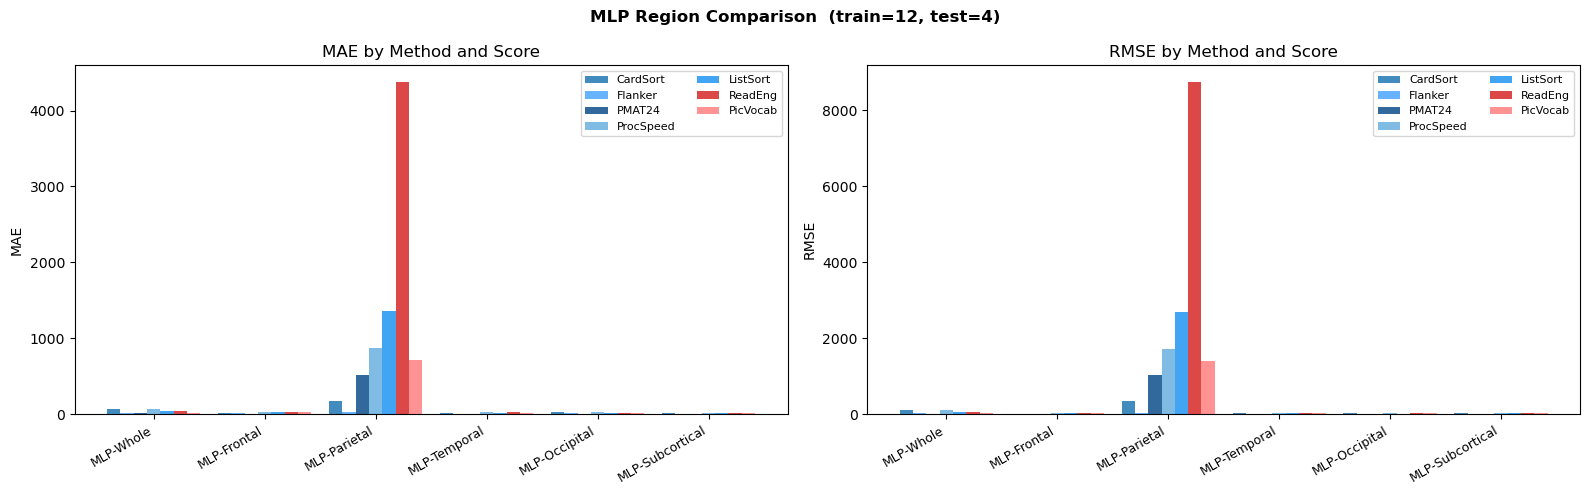

In [62]:
method_names = list(METHODS.keys())
x_pos = np.arange(len(method_names))
width = 0.12

# Color per target: fluid = blues, crystallized = reds
target_colors = {
    'CardSort':  '#1f77b4',
    'Flanker':   '#4da6ff',
    'PMAT24':    '#0d4f8b',
    'ProcSpeed': '#6ab0de',
    'ListSort':  '#2196F3',
    'ReadEng':   '#d62728',
    'PicVocab':  '#ff7f7f',
}

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax_idx, metric_key in enumerate(['MAE', 'RMSE']):
    ax = axes[ax_idx]
    for t_idx, (target, y) in enumerate(Y.items()):
        vals = [metrics(results[target][m][0], results[target][m][1])[metric_key]
                for m in method_names]
        ax.bar(x_pos + t_idx * width, vals, width,
               label=target, color=target_colors[target], alpha=0.85)
    ax.set_xticks(x_pos + width * (len(Y) - 1) / 2)
    ax.set_xticklabels(method_names, rotation=30, ha='right', fontsize=9)
    ax.set_ylabel(metric_key)
    ax.set_title(f'{metric_key} by Method and Score')
    ax.legend(fontsize=8, ncol=2)

fig.suptitle(f'MLP Region Comparison  (train={len(list(Y.values())[0])-TEST_SIZE}, test={TEST_SIZE})',
             fontsize=12, fontweight='bold')
fig.tight_layout()
plt.show()

## 10. Summary Table

## 11. Summary Table

In [63]:
rows = []
for target in TARGETS:
    for method in method_names:
        y_test, preds = results[target][method]
        m = metrics(y_test, preds)
        rows.append({'Target': target, 'Method': method,
                     'MAE': round(m['MAE'], 2),
                     'RMSE': round(m['RMSE'], 2)})

pd.DataFrame(rows).style \
  .background_gradient(subset=['MAE', 'RMSE'], cmap='RdYlGn_r')

,Target,Method,MAE,RMSE
0,CardSort,MLP-Whole,62.900000,110.520000
1,CardSort,MLP-Frontal,13.330000,15.600000
2,CardSort,MLP-Parietal,173.980000,335.750000
3,CardSort,MLP-Temporal,15.860000,20.470000
4,CardSort,MLP-Occipital,26.180000,32.760000
5,CardSort,MLP-Subcortical,18.060000,19.440000
6,Flanker,MLP-Whole,22.470000,37.100000
7,Flanker,MLP-Frontal,10.690000,15.200000
8,Flanker,MLP-Parietal,23.190000,39.100000
9,Flanker,MLP-Temporal,7.010000,7.990000
